# 05 · Final evaluation on the test sessions (used ONCE)

**Goal:** Measure how well the frozen finalists from Phase 4 estimate the winding temperature on the **6 test sessions** they have never seen. Then explain where they work and where they fail.

**Inputs:**
- `data/processed/features.parquet` (test rows, full 2 Hz resolution)
- `outputs/models/*.joblib` + `outputs/results/model_metadata.json` (finalists, frozen in Phase 4)
- `outputs/results/modelling_summary.json` (CV scores and the success targets set *before* this notebook)

**Outputs:**
- `outputs/results/test_metrics.csv`, `test_metrics_per_profile.csv`, `test_predictions.csv`, `evaluation_summary.json`
- Figures `eval_01` … `eval_13`

**Phase:** 5. **Rule:** no model, feature or setting is changed after this point because of these results.

## 1. Setup, and the time the test set was opened

In [1]:
import json
import random
import sys
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src import config
from src.data import load_split
from src.modelling import CoolantPlusOffset, regression_metrics
from src.plotting import COLORS, save_figure, use_style

random.seed(config.SEED)
np.random.seed(config.SEED)
use_style()

metadata = json.load(open(config.RESULTS_DIR / "model_metadata.json"))
modelling = json.load(open(config.RESULTS_DIR / "modelling_summary.json"))
FEATURES = metadata["features"]
split = load_split()
print("Finalists:", [m["model"] for m in metadata["finalists"]])

Finalists: ['M6 MLP (64-32)', 'M5 LightGBM', 'M3 Ridge']


In [2]:
feat = pd.read_parquet(config.PROJECT_DIR / "data" / "processed" / "features.parquet")
train = feat[feat[config.GROUP].isin(split["train_profiles"])]
test = feat[feat[config.GROUP].isin(split["test_profiles"])].copy()
del feat
test["minute"] = test.groupby(config.GROUP).cumcount() / config.SAMPLE_RATE_HZ / 60

test_opened_at = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print("TEST SET OPENED AT:", test_opened_at)
print("Test rows:", len(test), "| sessions:", sorted(test[config.GROUP].unique()))

TEST SET OPENED AT: 2026-10-10 09:24:52
Test rows: 141024 | sessions: [np.int64(6), np.int64(7), np.int64(21), np.int64(61), np.int64(66), np.int64(81)]


## 2. Predict the test sessions
- The **finalists** are loaded exactly as saved in Phase 4.
- The **baselines** B0 (training mean) and B1 (coolant + offset) are refitted on all training rows; they have no settings to tune.

Every prediction is made on full-resolution test rows (2 Hz), with no thinning.

In [3]:
y_test = test[config.TARGET].astype("float64").to_numpy()
predictions = {}

b0 = DummyRegressor(strategy="mean").fit(train[FEATURES], train[config.TARGET])
predictions["B0 mean"] = b0.predict(test[FEATURES])
b1 = CoolantPlusOffset().fit(train[FEATURES], train[config.TARGET])
predictions["B1 coolant + offset"] = b1.predict(test[FEATURES])

models = {}
for info in metadata["finalists"]:
    models[info["model"]] = joblib.load(config.PROJECT_DIR / info["file"])
    predictions[info["model"]] = models[info["model"]].predict(test[FEATURES])
FINAL = metadata["finalists"][0]["model"]
SECOND = metadata["finalists"][1]["model"]
print("Final model:", FINAL, "| runner-up:", SECOND)

Final model: M6 MLP (64-32) | runner-up: M5 LightGBM


## 3. Overall test metrics
- **MSE** (°C²), **RMSE** and **MAE** (°C), **R²**, the **maximum absolute error**, the **95th-percentile absolute error** (95 % of errors are smaller than this), and the **mean signed error** = mean(predicted − actual). Negative means the model under-predicts on average.
- **Session-mean MAE:** the MAE of each session averaged with equal weight, so long sessions don't dominate (plan v2).

In [4]:
rows = []
for name, pred in predictions.items():
    m = regression_metrics(y_test, pred)
    per_session_mae = [regression_metrics(y_test[mask], pred[mask])["mae"]
                       for mask in [(test[config.GROUP] == p).to_numpy() for p in split["test_profiles"]]]
    m["session_mean_mae"] = float(np.mean(per_session_mae))
    m["model"] = name
    rows.append(m)
test_metrics = pd.DataFrame(rows).set_index("model").sort_values("rmse")
test_metrics.to_csv(config.RESULTS_DIR / "test_metrics.csv")
test_metrics.round(3)

,mse,rmse,mae,r2,max_abs_error,p95_abs_error,mean_signed_error,session_mean_mae
model,,,,,,,,
M3 Ridge,24.665,4.966,2.993,0.963,73.573,9.030,0.380,2.847
M5 LightGBM,26.065,5.105,2.860,0.961,74.873,9.877,-0.873,2.380
M6 MLP (64-32),36.058,6.005,3.693,0.946,60.312,14.597,-1.946,2.991
B1 coolant + offset,599.458,24.484,20.147,0.106,72.000,50.917,2.404,19.543
B0 mean,672.916,25.941,22.225,-0.004,63.495,45.961,-1.626,23.078


## 4. Metrics per test session

In [5]:
per_rows = []
for p in split["test_profiles"]:
    mask = (test[config.GROUP] == p).to_numpy()
    for name, pred in predictions.items():
        m = regression_metrics(y_test[mask], pred[mask])
        per_rows.append({"profile_id": p, "model": name, "hours": round(mask.sum() / 7200, 3),
                         "winding_min": float(y_test[mask].min()), "winding_max": float(y_test[mask].max()), **m})
per_profile = pd.DataFrame(per_rows)
per_profile.to_csv(config.RESULTS_DIR / "test_metrics_per_profile.csv", index=False)
per_profile[per_profile["model"] == FINAL][["profile_id", "hours", "winding_min", "winding_max", "rmse", "mae", "r2",
                                             "max_abs_error", "mean_signed_error"]].round(3)

,profile_id,hours,winding_min,winding_max,rmse,mae,r2,max_abs_error,mean_signed_error
2,6,5.609,19.033,121.034,9.430,7.635,0.868,21.873,-6.599
7,7,2.035,19.851,39.956,1.226,0.800,0.965,6.175,0.297
12,21,2.406,19.776,104.791,5.988,3.318,0.954,60.312,-1.252
17,61,2.016,43.453,129.665,3.620,2.371,0.977,22.669,-0.538
22,66,5.066,28.030,128.342,3.708,2.194,0.973,34.226,0.122
27,81,2.454,23.601,104.656,2.998,1.630,0.976,17.923,0.723


## 5. Figures 1–6: predicted vs actual over time, one per test session
These are the most important plots of the project. The copper line is the **real** winding temperature, the black line is our final model's estimate (the grey dashed line is the runner-up). The lower panel shows the error (predicted − actual): below 0 means **under-prediction**, the dangerous direction.

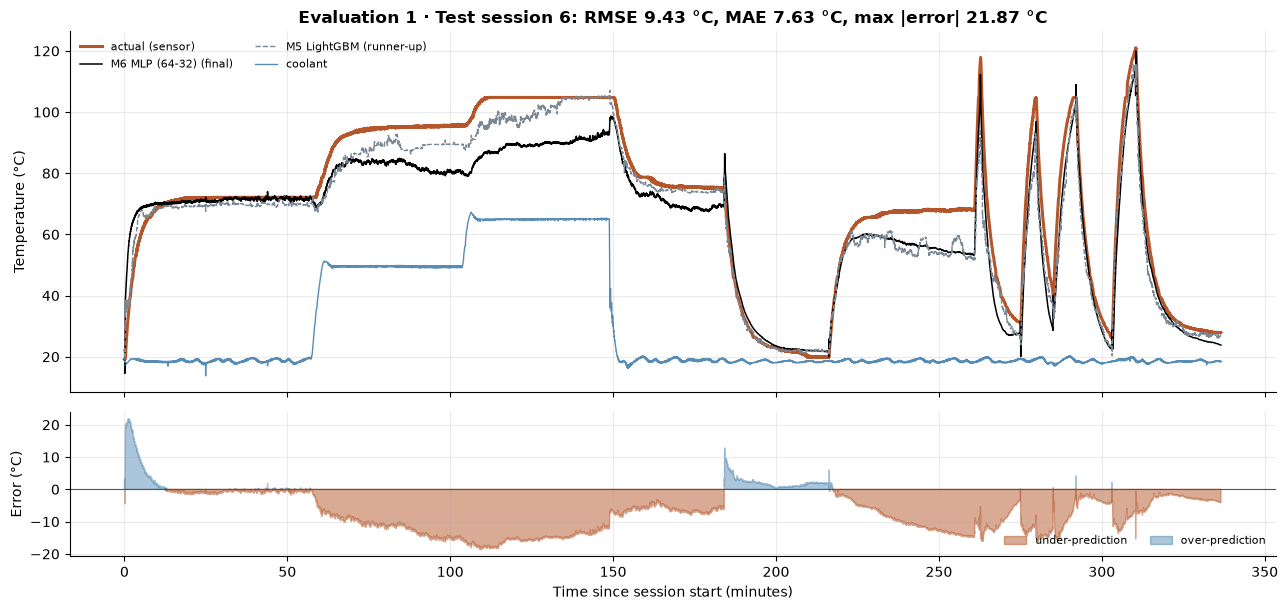

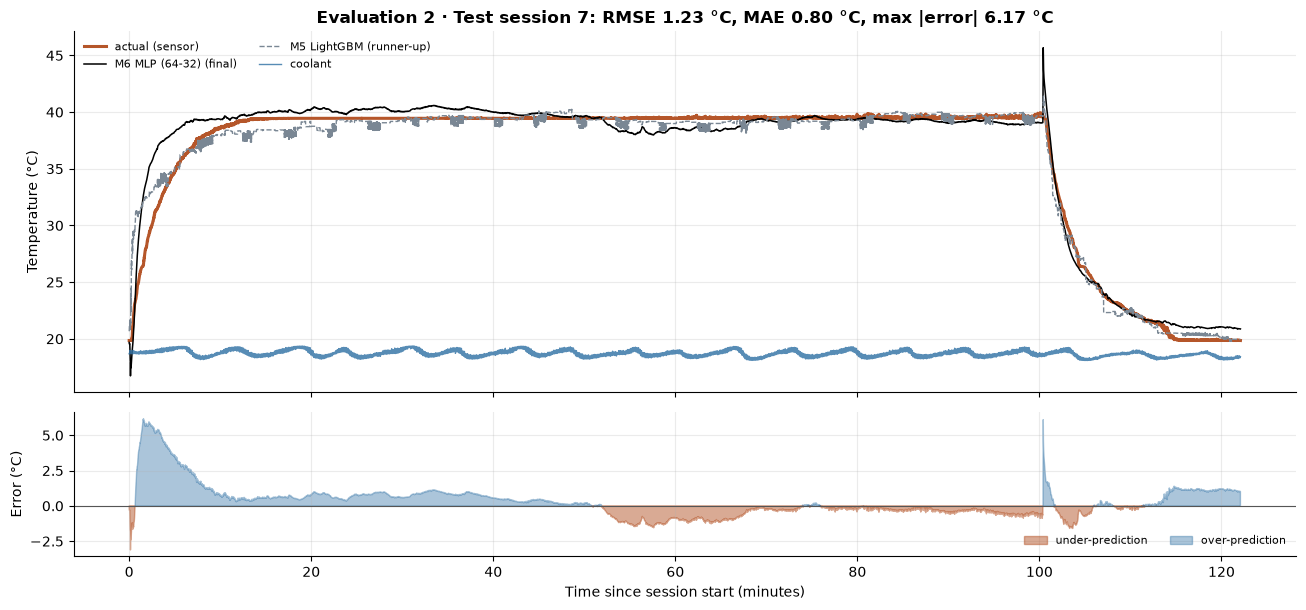

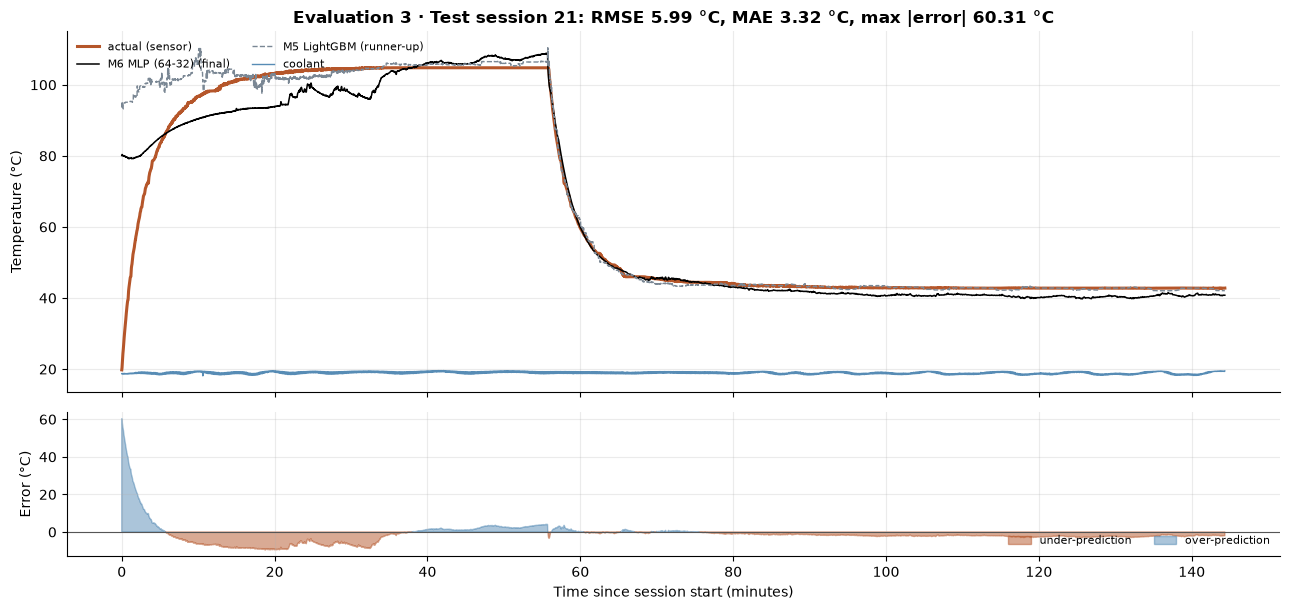

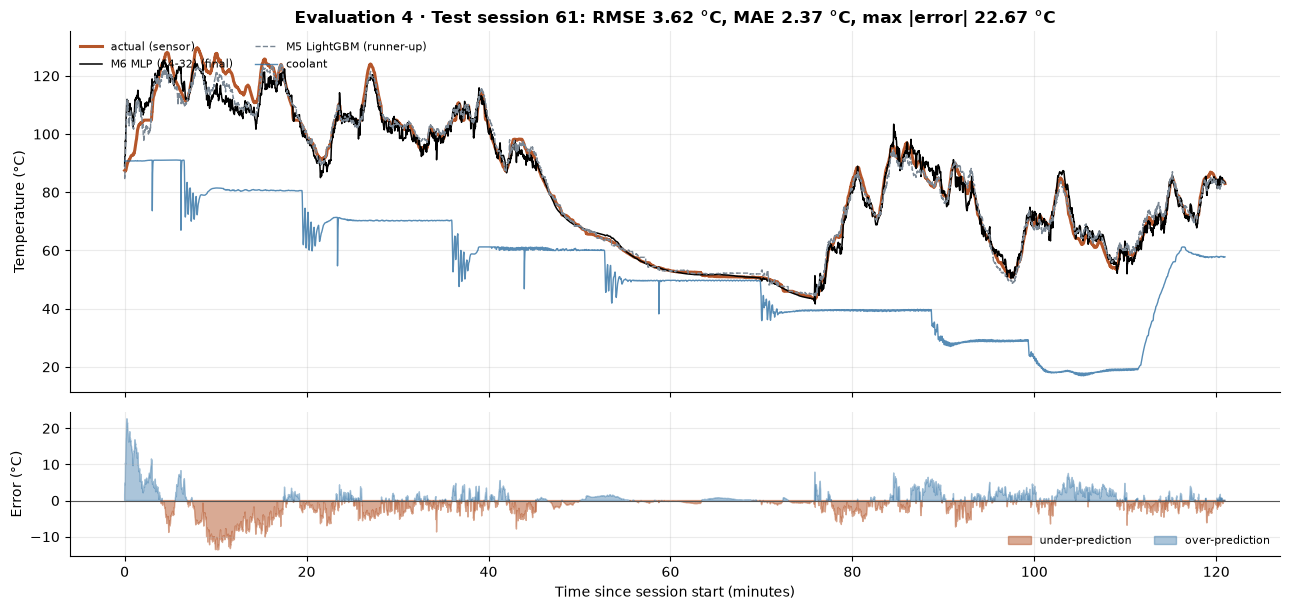

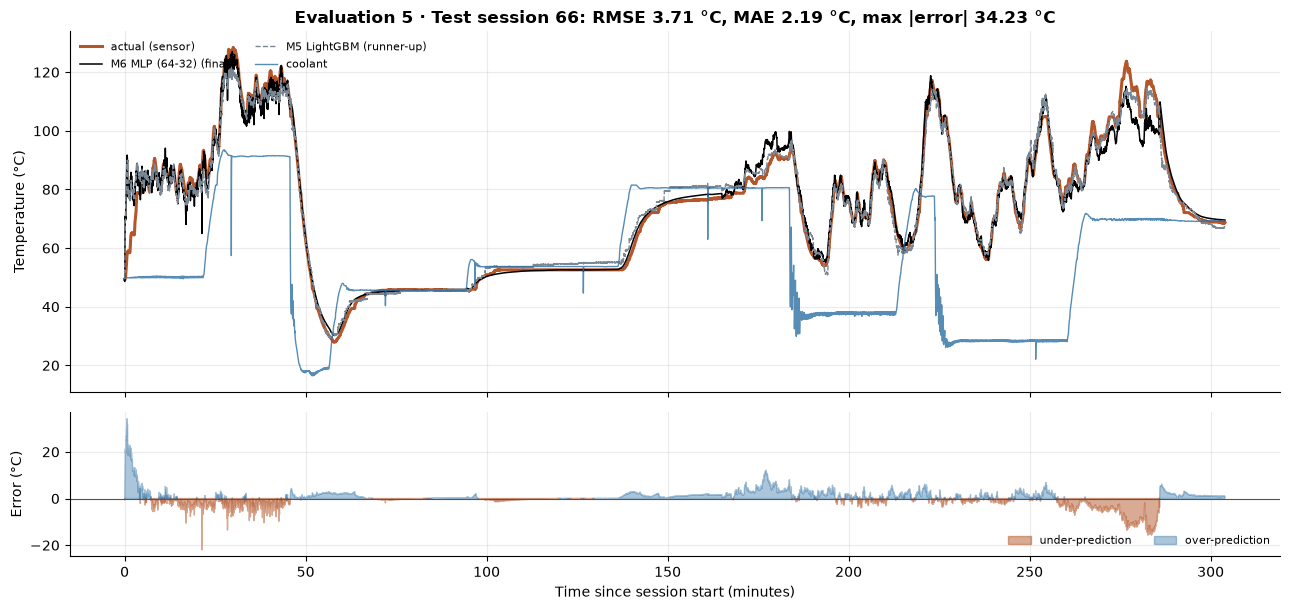

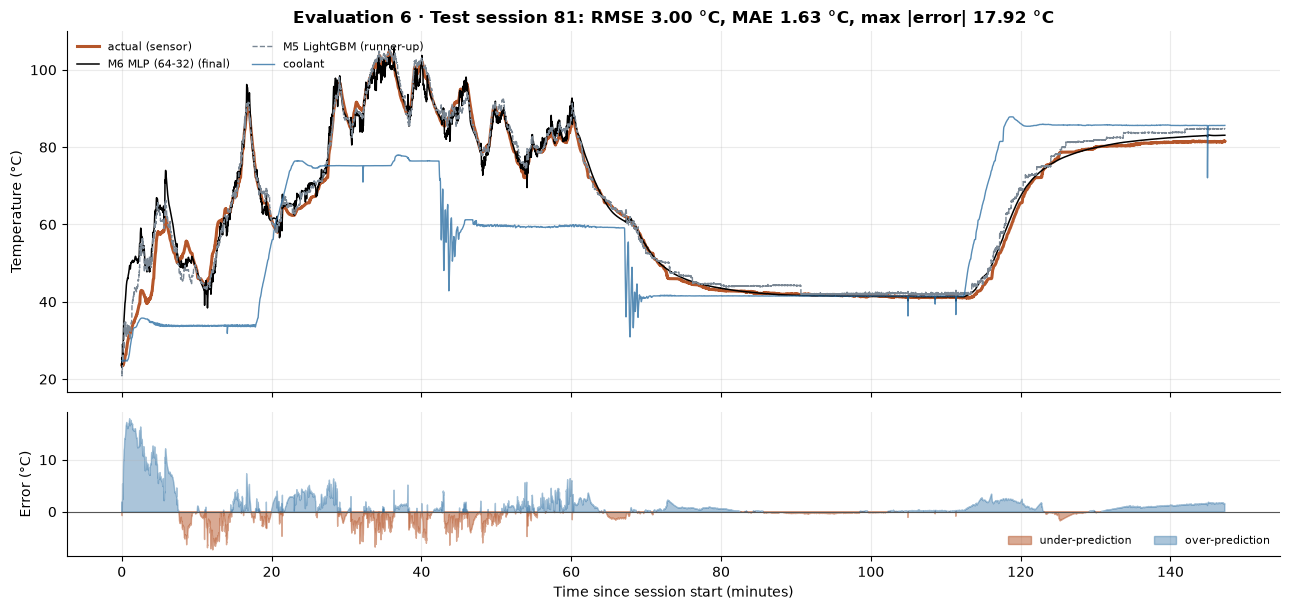

In [6]:
for k, p in enumerate(split["test_profiles"], start=1):
    mask = (test[config.GROUP] == p).to_numpy()
    minutes = test.loc[mask, "minute"].to_numpy()
    fig, (ax, axe) = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
    ax.plot(minutes, y_test[mask], color=COLORS["stator_winding"], lw=2.2, label="actual (sensor)")
    ax.plot(minutes, predictions[FINAL][mask], color="black", lw=1.1, label=f"{FINAL} (final)")
    ax.plot(minutes, predictions[SECOND][mask], color="#7a8794", lw=1, ls="--", label=f"{SECOND} (runner-up)")
    ax.plot(minutes, test.loc[mask, "coolant"], color=COLORS["coolant"], lw=1, alpha=0.8, label="coolant")
    ax.set_ylabel("Temperature (°C)")
    m = regression_metrics(y_test[mask], predictions[FINAL][mask])
    ax.set_title(f"Evaluation {k} · Test session {p}: RMSE {m['rmse']:.2f} °C, MAE {m['mae']:.2f} °C, max |error| {m['max_abs_error']:.2f} °C")
    ax.legend(loc="upper left", ncol=2, fontsize=8)
    err = predictions[FINAL][mask] - y_test[mask]
    axe.fill_between(minutes, err, 0, where=err < 0, color=COLORS["stator_winding"], alpha=0.5, label="under-prediction")
    axe.fill_between(minutes, err, 0, where=err >= 0, color=COLORS["coolant"], alpha=0.4, label="over-prediction")
    axe.axhline(0, color="#555555", lw=0.8)
    axe.set_ylabel("Error (°C)")
    axe.set_xlabel("Time since session start (minutes)")
    axe.legend(loc="lower right", ncol=2, fontsize=8)
    fig.tight_layout()
    save_figure(fig, f"eval_{k:02d}_test_session_{p}.png")
    plt.show()

## 6. Figure 7: how are the errors distributed?

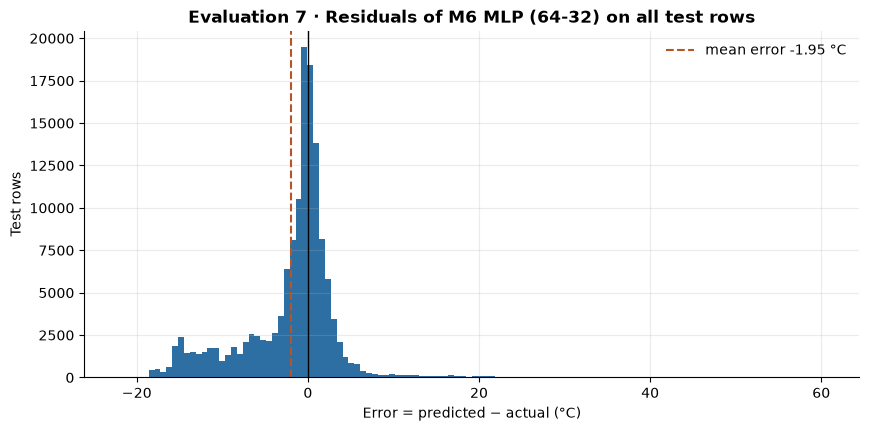

Errors within ±2 °C: 54.5 % | within ±5 °C: 75.6 %


In [7]:
err_final = predictions[FINAL] - y_test
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(err_final, bins=120, color=COLORS["coolant"])
ax.axvline(0, color="black", lw=1)
ax.axvline(err_final.mean(), color=COLORS["stator_winding"], lw=1.5, ls="--", label=f"mean error {err_final.mean():+.2f} °C")
ax.set_xlabel("Error = predicted − actual (°C)")
ax.set_ylabel("Test rows")
ax.set_title(f"Evaluation 7 · Residuals of {FINAL} on all test rows")
ax.legend()
save_figure(fig, "eval_07_residual_histogram.png")
plt.show()
print(f"Errors within ±2 °C: {100 * np.mean(np.abs(err_final) <= 2):.1f} % | within ±5 °C: {100 * np.mean(np.abs(err_final) <= 5):.1f} %")

## 7. Figure 8: predicted vs actual (all test rows)
Perfect predictions would lie exactly on the dashed y = x line.

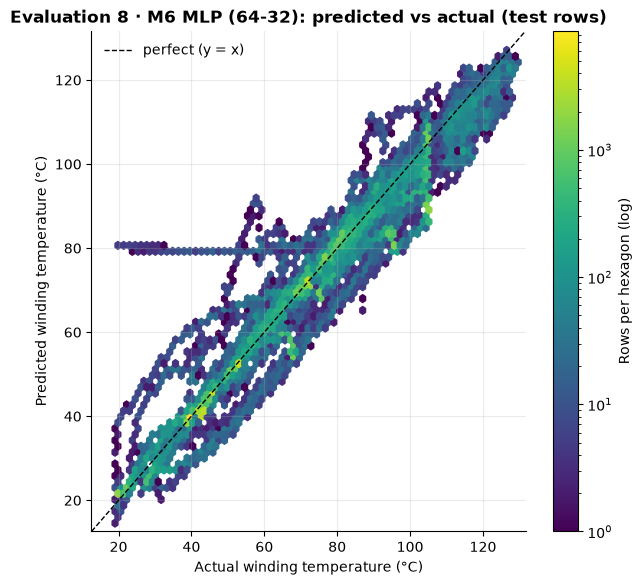

In [8]:
fig, ax = plt.subplots(figsize=(7, 6.5))
hb = ax.hexbin(y_test, predictions[FINAL], gridsize=70, bins="log", mincnt=1, cmap="viridis")
lims = [min(y_test.min(), predictions[FINAL].min()) - 2, max(y_test.max(), predictions[FINAL].max()) + 2]
ax.plot(lims, lims, color="black", ls="--", lw=1, label="perfect (y = x)")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual winding temperature (°C)")
ax.set_ylabel("Predicted winding temperature (°C)")
ax.set_title(f"Evaluation 8 · {FINAL}: predicted vs actual (test rows)")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="Rows per hexagon (log)")
save_figure(fig, "eval_08_predicted_vs_actual.png")
plt.show()

## 8. Figure 9: does the model get worse when the motor is hot?
We group the test rows into 10 °C bands of the **actual** temperature and plot the mean absolute error and the mean signed error per band.

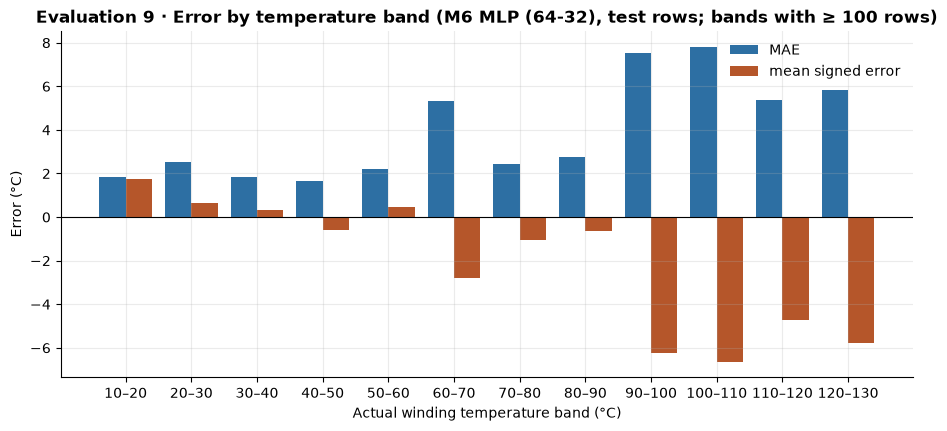

,rows,mae,mean_signed
band,,,
"(10, 20]",1649,1.817,1.727
"(20, 30]",6226,2.522,0.650
"(30, 40]",16111,1.827,0.310
"(40, 50]",22240,1.651,-0.607
"(50, 60]",12698,2.198,0.453
"(60, 70]",13739,5.313,-2.807
"(70, 80]",21199,2.449,-1.051
"(80, 90]",13400,2.760,-0.634
"(90, 100]",12295,7.527,-6.216


In [9]:
bands = pd.cut(y_test, bins=np.arange(10, 160, 10))
band_table = pd.DataFrame({"band": bands, "abs_err": np.abs(err_final), "err": err_final}).groupby("band", observed=True).agg(
    rows=("abs_err", "size"), mae=("abs_err", "mean"), mean_signed=("err", "mean"))
band_table = band_table[band_table["rows"] >= 100]
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(band_table))
ax.bar(x - 0.2, band_table["mae"], width=0.4, color=COLORS["coolant"], label="MAE")
ax.bar(x + 0.2, band_table["mean_signed"], width=0.4, color=COLORS["stator_winding"], label="mean signed error")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"{int(b.left)}–{int(b.right)}" for b in band_table.index], rotation=0)
ax.set_xlabel("Actual winding temperature band (°C)")
ax.set_ylabel("Error (°C)")
ax.set_title(f"Evaluation 9 · Error by temperature band ({FINAL}, test rows; bands with ≥ 100 rows)")
ax.legend()
save_figure(fig, "eval_09_error_by_temperature.png")
plt.show()
band_table.round(3)

## 9. Figure 10: errors near the start of a session (the EWMA warm-up)
Phase 3 predicted larger errors in the first minutes of a session, while the long EWMAs have little history. We check this with the mean absolute error per 5-minute window since the session start.

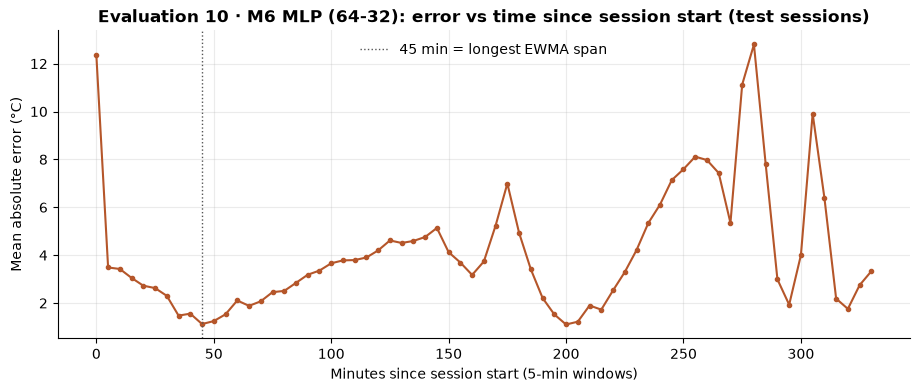

MAE in the first 45 min: 3.665 °C | after 45 min: 3.701 °C


In [10]:
win = (test["minute"] // 5) * 5
warm = pd.DataFrame({"win": win.to_numpy(), "abs_err": np.abs(err_final)}).groupby("win")["abs_err"].agg(["mean", "size"])
warm = warm[warm["size"] >= 600]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(warm.index, warm["mean"], marker="o", ms=3, color=COLORS["stator_winding"])
ax.axvline(45, color="#555555", ls=":", lw=1, label="45 min = longest EWMA span")
ax.set_xlabel("Minutes since session start (5-min windows)")
ax.set_ylabel("Mean absolute error (°C)")
ax.set_title(f"Evaluation 10 · {FINAL}: error vs time since session start (test sessions)")
ax.legend()
save_figure(fig, "eval_10_error_vs_session_time.png")
plt.show()
first_45 = float(np.abs(err_final)[test["minute"].to_numpy() < 45].mean())
after_45 = float(np.abs(err_final)[test["minute"].to_numpy() >= 45].mean())
print(f"MAE in the first 45 min: {first_45:.3f} °C | after 45 min: {after_45:.3f} °C")

## 10. Figure 11: which inputs matter? (permutation importance)
**Permutation importance:** shuffle one input column (breaking its link to the target) and measure how much the RMSE gets worse. A big increase means the model relies on that input. We use every 10th test row (2.5 % of all rows) and 3 shuffles per feature, to keep it quick.

Because our 45 features come in correlated families (e.g. `i_s` and its 4 EWMAs), shuffling one member hurts little: the others still carry the information. So we also shuffle **whole families together** (grouped importance), which matches the physics question "how much does the model rely on current, coolant, …?".

This is *interpretation only*, after the single evaluation. No model or feature is changed because of it.

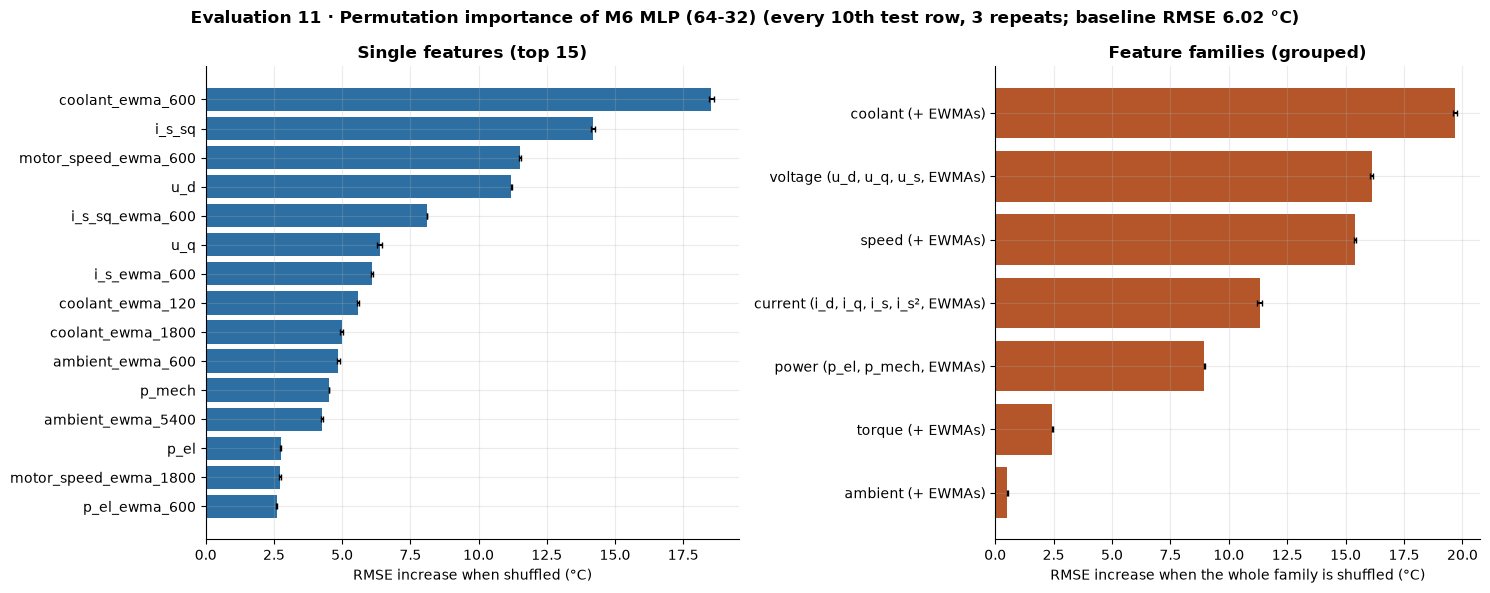

,family,n_features,rmse_increase,std
5,coolant (+ EWMAs),5,19.670,0.094
1,"voltage (u_d, u_q, u_s, EWMAs)",7,16.110,0.054
3,speed (+ EWMAs),5,15.398,0.047
0,"current (i_d, i_q, i_s, i_s², EWMAs)",12,11.320,0.100
2,"power (p_el, p_mech, EWMAs)",6,8.958,0.040
4,torque (+ EWMAs),5,2.445,0.034
6,ambient (+ EWMAs),5,0.519,0.011


In [11]:
final_model = models[FINAL]
sample = test.iloc[::10]
X_s, y_s = sample[FEATURES], sample[config.TARGET].astype("float64")
pi = permutation_importance(final_model, X_s, y_s, scoring="neg_root_mean_squared_error", n_repeats=3,
                            random_state=config.SEED, n_jobs=1)
imp = pd.DataFrame({"feature": FEATURES, "rmse_increase": pi.importances_mean, "std": pi.importances_std}).sort_values("rmse_increase", ascending=False)
imp.round(4).to_csv(config.RESULTS_DIR / "permutation_importance.csv", index=False)

families = {
    "current (i_d, i_q, i_s, i_s², EWMAs)": [f for f in FEATURES if f.startswith(("i_d", "i_q", "i_s"))],
    "voltage (u_d, u_q, u_s, EWMAs)": [f for f in FEATURES if f.startswith(("u_d", "u_q", "u_s"))],
    "power (p_el, p_mech, EWMAs)": [f for f in FEATURES if f.startswith(("p_el", "p_mech"))],
    "speed (+ EWMAs)": [f for f in FEATURES if f.startswith("motor_speed")],
    "torque (+ EWMAs)": [f for f in FEATURES if f.startswith("torque")],
    "coolant (+ EWMAs)": [f for f in FEATURES if f.startswith("coolant")],
    "ambient (+ EWMAs)": [f for f in FEATURES if f.startswith("ambient")],
}
assert sum(len(v) for v in families.values()) == len(FEATURES)
base_rmse = regression_metrics(y_s, final_model.predict(X_s))["rmse"]
rng = np.random.default_rng(config.SEED)
fam_rows = []
for fam, cols in families.items():
    increases = []
    for _ in range(3):
        X_perm = X_s.copy()
        order = rng.permutation(len(X_perm))
        X_perm[cols] = X_perm[cols].to_numpy()[order]
        increases.append(regression_metrics(y_s, final_model.predict(X_perm))["rmse"] - base_rmse)
    fam_rows.append({"family": fam, "n_features": len(cols), "rmse_increase": float(np.mean(increases)), "std": float(np.std(increases))})
fam_imp = pd.DataFrame(fam_rows).sort_values("rmse_increase", ascending=False)
fam_imp.round(4).to_csv(config.RESULTS_DIR / "permutation_importance_grouped.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})
top = imp.head(15).iloc[::-1]
axes[0].barh(top["feature"], top["rmse_increase"], xerr=top["std"], color=COLORS["coolant"], capsize=2)
axes[0].set_xlabel("RMSE increase when shuffled (°C)")
axes[0].set_title("Single features (top 15)")
fam_plot = fam_imp.iloc[::-1]
axes[1].barh(fam_plot["family"], fam_plot["rmse_increase"], xerr=fam_plot["std"], color=COLORS["stator_winding"], capsize=2)
axes[1].set_xlabel("RMSE increase when the whole family is shuffled (°C)")
axes[1].set_title("Feature families (grouped)")
fig.suptitle(f"Evaluation 11 · Permutation importance of {FINAL} (every 10th test row, 3 repeats; baseline RMSE {base_rmse:.2f} °C)", fontweight="bold")
fig.tight_layout()
save_figure(fig, "eval_11_permutation_importance.png")
plt.show()
fam_imp.round(3)

## 11. Figure 12: all models, CV score vs test score

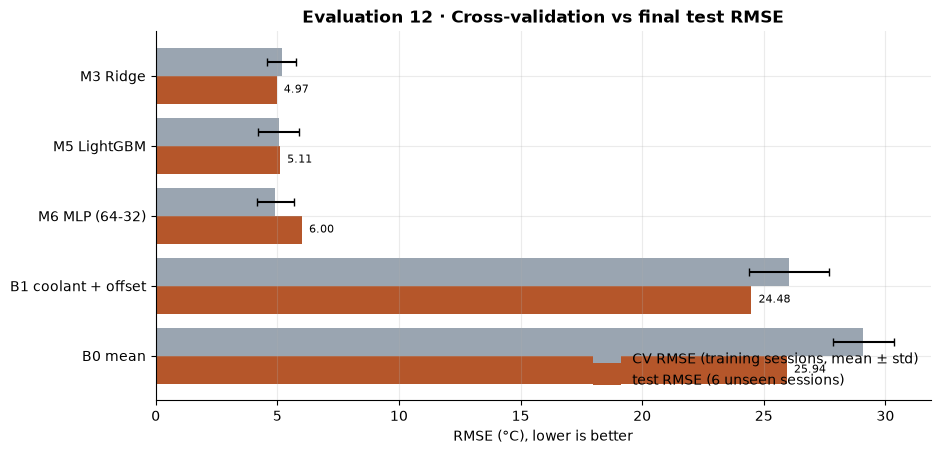

,test_rmse,cv_rmse,cv_std,gap
model,,,,
B0 mean,25.941,29.088,1.258,-3.147
B1 coolant + offset,24.484,26.033,1.636,-1.549
M6 MLP (64-32),6.005,4.919,0.763,1.086
M5 LightGBM,5.105,5.061,0.836,0.044
M3 Ridge,4.966,5.172,0.576,-0.205


In [12]:
cv_table = pd.DataFrame(modelling["cv_table"]).set_index("model")
compare = test_metrics[["rmse"]].rename(columns={"rmse": "test_rmse"}).join(cv_table[["rmse_mean", "rmse_std"]].rename(columns={"rmse_mean": "cv_rmse", "rmse_std": "cv_std"}))
compare["gap"] = compare["test_rmse"] - compare["cv_rmse"]
compare = compare.sort_values("test_rmse", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.8))
yp = np.arange(len(compare))
ax.barh(yp + 0.2, compare["cv_rmse"], height=0.4, xerr=compare["cv_std"], color="#9aa5b1", capsize=3, label="CV RMSE (training sessions, mean ± std)")
ax.barh(yp - 0.2, compare["test_rmse"], height=0.4, color=COLORS["stator_winding"], label="test RMSE (6 unseen sessions)")
for i, v in enumerate(compare["test_rmse"]):
    ax.text(v + 0.3, yp[i] - 0.2, f"{v:.2f}", va="center", fontsize=8)
ax.set_yticks(yp)
ax.set_yticklabels(compare.index)
ax.set_xlabel("RMSE (°C), lower is better")
ax.set_title("Evaluation 12 · Cross-validation vs final test RMSE")
ax.legend(loc="lower right")
save_figure(fig, "eval_12_cv_vs_test.png")
plt.show()
compare.round(3)

## 12. Under-prediction analysis (plan N8): the dangerous mistakes
"Hot" is defined **from the training data, not the test data**: the 90th percentile of the training winding temperatures, **104.79 °C** (`eda_summary.json`). We report:
- the largest under-prediction;
- among hot test rows, how often the model says the winding is more than 5 °C cooler than it really is.

In [13]:
eda = json.load(open(config.RESULTS_DIR / "eda_summary.json"))
HOT = float(eda["target_train_stats"]["90%"])
hot = y_test >= HOT
under = {}
for name in [FINAL, SECOND]:
    e = predictions[name] - y_test
    worst = int(np.argmin(e))
    under[name] = {
        "hot_threshold_c": HOT,
        "hot_rows": int(hot.sum()),
        "hot_share_of_test_rows": float(hot.mean()),
        "largest_under_prediction_c": float(e.min()),
        "largest_under_session": int(test[config.GROUP].iloc[worst]),
        "largest_under_minute": float(test["minute"].iloc[worst]),
        "largest_under_actual_c": float(y_test[worst]),
        "pct_hot_rows_under_by_more_than_5c": float(100 * np.mean(e[hot] < -5)) if hot.any() else None,
        "pct_all_rows_under_by_more_than_5c": float(100 * np.mean(e < -5)),
        "mean_signed_error_hot_rows": float(e[hot].mean()) if hot.any() else None,
    }
pd.DataFrame(under).T.round(3)

,hot_threshold_c,hot_rows,hot_share_of_test_rows,largest_under_prediction_c,largest_under_session,largest_under_minute,largest_under_actual_c,pct_hot_rows_under_by_more_than_5c,pct_all_rows_under_by_more_than_5c,mean_signed_error_hot_rows
M6 MLP (64-32),104.791,14496.0,0.103,-22.027,66.0,21.333,86.994,52.014,21.12,-6.477
M5 LightGBM,104.791,14496.0,0.103,-33.261,6.0,263.358,100.073,26.959,13.88,-2.624


## 13. Generalisation gap and the success targets set in Phase 4

In [14]:
targets = modelling["success_target"]
final_test_rmse = float(test_metrics.loc[FINAL, "rmse"])
target_1_met = final_test_rmse <= targets["test_rmse_max"]
target_2_met = final_test_rmse <= targets["test_rmse_max_vs_b1"]
print(f"Final model {FINAL}: CV RMSE {compare.loc[FINAL, 'cv_rmse']:.3f} °C -> test RMSE {final_test_rmse:.3f} °C (gap {compare.loc[FINAL, 'gap']:+.3f} °C)")
print(f"Target 1 (test RMSE <= {targets['test_rmse_max']:.1f} °C): {'MET' if target_1_met else 'NOT MET'}")
print(f"Target 2 (test RMSE <= {targets['test_rmse_max_vs_b1']:.2f} °C, half of B1's CV RMSE): {'MET' if target_2_met else 'NOT MET'}")

Final model M6 MLP (64-32): CV RMSE 4.919 °C -> test RMSE 6.005 °C (gap +1.086 °C)
Target 1 (test RMSE <= 6.5 °C): MET
Target 2 (test RMSE <= 13.02 °C, half of B1's CV RMSE): MET


## 14. Save the predictions and every number
`test_predictions.csv` lets Phase 6 (the safety alarm) and the demo app reuse these exact predictions **without** running the models on the test set again.

In [15]:
pred_table = pd.DataFrame({config.GROUP: test[config.GROUP].to_numpy(), "minute": test["minute"].round(4).to_numpy(),
                           "actual": np.round(y_test, 3), "coolant": test["coolant"].round(3).to_numpy()})
for name in [FINAL, SECOND] + [m["model"] for m in metadata["finalists"][2:]] + ["B1 coolant + offset"]:
    pred_table["pred_" + name.split(" ")[0].lower()] = np.round(predictions[name], 3)
pred_table.to_csv(config.RESULTS_DIR / "test_predictions.csv", index=False)

summary = {
    "test_opened_at": test_opened_at,
    "final_model": FINAL, "runner_up": SECOND,
    "test_rows": int(len(test)), "test_sessions": split["test_profiles"],
    "overall": test_metrics.round(4).reset_index().to_dict(orient="records"),
    "cv_vs_test": compare.round(4).reset_index().to_dict(orient="records"),
    "under_prediction": under,
    "warmup_mae": {"first_45_min": round(first_45, 4), "after_45_min": round(after_45, 4)},
    "error_bands": {str(k): {"rows": int(v["rows"]), "mae": round(float(v["mae"]), 4), "mean_signed": round(float(v["mean_signed"]), 4)}
                    for k, v in band_table.iterrows()},
    "within_2c_pct": float(100 * np.mean(np.abs(err_final) <= 2)), "within_5c_pct": float(100 * np.mean(np.abs(err_final) <= 5)),
    "permutation_base_rmse_sample": round(base_rmse, 4),
    "grouped_importance": fam_imp.round(4).to_dict(orient="records"),
    "top10_importance": imp.head(10).round(4).to_dict(orient="records"),
    "targets": {**targets, "target_1_met": bool(target_1_met), "target_2_met": bool(target_2_met)},
}
with open(config.RESULTS_DIR / "evaluation_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved test_predictions.csv and evaluation_summary.json")

Saved test_predictions.csv and evaluation_summary.json


## 15. Interpretation (numbers from the outputs above and `evaluation_summary.json`; this cell was added after the single run, with no re-execution)

**Test set opened once, at 2026-10-10 09:24:52.** Nothing below changed any model.

**Overall (6 unseen sessions, 141,024 rows at 2 Hz):**

| Model | Test RMSE | MAE | R² | p95 abs error | Mean signed | Session-mean MAE | CV RMSE | Gap |
|---|---|---|---|---|---|---|---|---|
| M3 Ridge | **4.966** | 2.993 | 0.963 | 9.030 | +0.380 | 2.847 | 5.172 | −0.205 |
| M5 LightGBM | 5.105 | **2.860** | 0.961 | 9.877 | −0.873 | **2.380** | 5.061 | +0.044 |
| M6 MLP (final by our rule) | 6.005 | 3.693 | 0.946 | 14.597 | −1.946 | 2.991 | 4.919 | +1.086 |
| B1 coolant + offset | 24.484 | 20.147 | 0.106 | 50.917 | +2.404 | 19.543 | 26.033 | −1.549 |
| B0 mean | 25.941 | 22.225 | −0.004 | 45.961 | −1.626 | 23.078 | 29.088 | −3.147 |

- **Both success targets are met.** The MLP's test RMSE of 6.005 °C ≤ 6.5 °C, and ≤ 13.02 °C (half of B1). All finalists beat the baselines by about 4–5×.
- **The CV winner came last among the finalists on the test set.** In CV the top five models were 4.92–5.20 °C apart, *less* than their fold spread (± 0.58–0.84 °C), so CV could not really separate them. On the test set Ridge (4.966) and LightGBM (5.105) beat the MLP (6.005). We **keep the pre-registered final model** (MLP) for reporting, because choosing again now would be choosing on the test set. **Lesson:** next time we would pre-register a "simplest model within one standard deviation of the best" rule, which would have picked Ridge from the CV numbers alone.
- **Per session (MLP):** five of six sessions have RMSE 1.23–5.99 °C. **Session 6 is the hard one (RMSE 9.43 °C, mean signed −6.60 °C):** while the coolant was raised to about 50–65 °C under load, the MLP under-predicted the winding by 10–18 °C for over an hour. LightGBM tracked it more closely.
- **Hot = danger zone:** above 90 °C the MLP's errors grow (MAE 7.5–7.8 °C at 90–110 °C) and are mostly **under-predictions** (mean signed −6.2 to −6.6 °C).
  - Of the hot rows (≥ 104.79 °C, the training 90th percentile; 10.3 % of test rows), the MLP under-predicts by more than 5 °C in **52.0 %**, against 27.0 % for LightGBM.
  - Largest under-prediction: MLP −22.03 °C (session 66, minute 21.3); LightGBM −33.26 °C (session 6, minute 263.4).
- **Session starts:** the biggest single error (+60.31 °C, session 21, minute 0) is an over-prediction when a cold motor starts directly under heavy load. The EWMA memories begin at the current value, so they "think" the load has lasted a long time. The first 5-minute window has a mean error of about 12 °C (Figure 10), and Phase 6 quantifies it. Averaged over the first 45 minutes, the MAE (3.665 °C) is no worse than after 45 minutes (3.701 °C), because the problem lasts only a few minutes.
- **Physics check of the importances (grouped, MLP):** coolant 19.67 > voltage 16.11 > speed 15.40 > current 11.32 > power 8.96 > torque 2.45 > ambient 0.52 (RMSE increase in °C). This matches physics:
  - coolant sets the temperature floor;
  - current (I²R) heats the copper;
  - voltage and speed describe the operating point (iron losses grow with speed);
  - torque is nearly a copy of i_q (r = 0.9965), so it adds little;
  - ambient varies over only a narrow range (8.78–30.71 °C).
  Correlated families share importance, so read the grouped chart rather than single features.
- **Accuracy in plain words (MLP):** 54.5 % of test predictions are within ±2 °C and 75.6 % within ±5 °C.
